# Real-Time Credit Card Fraud Detection Engine
**Goal:** train fraud classifiers, apply **SMOTE**, compare performance **before vs after SMOTE**, and pick the best model.

**Pipeline:** Load → EDA → Cleaning → Split → Scaling → Baseline models (no SMOTE) → SMOTE → Models again (with SMOTE) → Comparison → Best model → Save + real-time inference

> Put `creditcard.csv` in the same folder as this notebook (or change `DATA_PATH`).
> Install once if needed: `pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost lightgbm joblib`

## 1. Imports & Settings

In [1]:
import warnings, time, joblib
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, classification_report)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

DATA_PATH = 'creditcard.csv'
RANDOM_STATE = 42
sns.set_style('whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

## 2. Load Data

In [2]:
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


## 3. Exploratory Data Analysis (EDA)

In [3]:
print('Missing values :', df.isnull().sum().sum())
print('Duplicate rows :', df.duplicated().sum())
df.describe().T[['mean','std','min','max']].head(8)

Missing values : 0


Duplicate rows : 1081


,mean,std,min,max
Time,94813.8596,47488.1460,0.0000,172792.0000
V1,0.0000,1.9587,-56.4075,2.4549
V2,0.0000,1.6513,-72.7157,22.0577
V3,-0.0000,1.5163,-48.3256,9.3826
V4,0.0000,1.4159,-5.6832,16.8753
V5,0.0000,1.3802,-113.7433,34.8017
V6,0.0000,1.3323,-26.1605,73.3016
V7,-0.0000,1.2371,-43.5572,120.5895


Class
0    284315
1       492
Name: count, dtype: int64
Fraud share: 0.1727%
A model that predicts 'legit' for everything scores 99.83% accuracy -> accuracy alone is misleading!


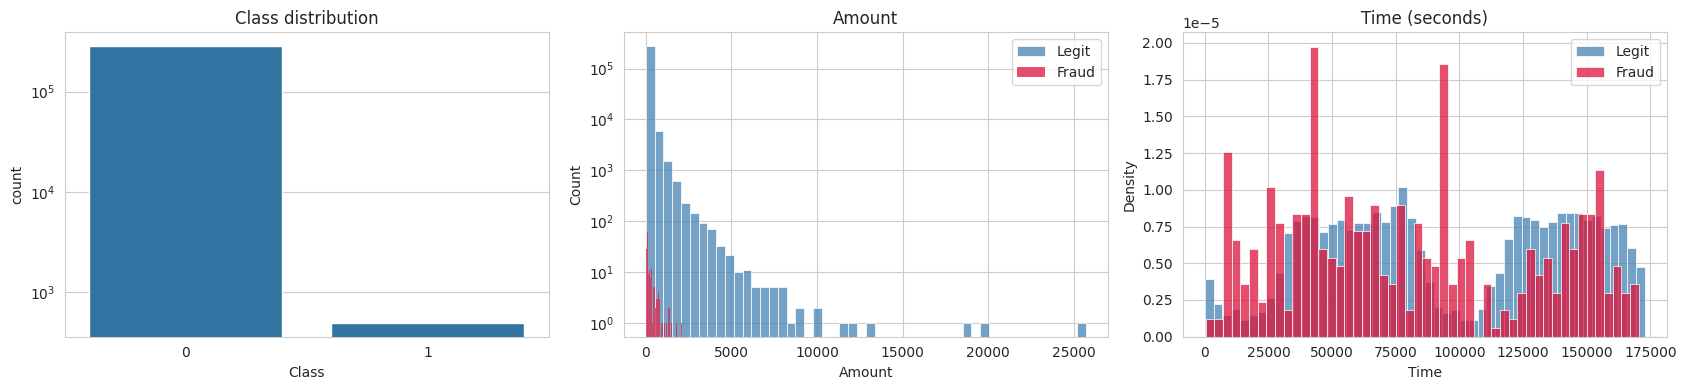

In [4]:
counts = df['Class'].value_counts()
print(counts)
print(f"Fraud share: {counts[1]/len(df)*100:.4f}%")
print(f"A model that predicts 'legit' for everything scores {counts[0]/len(df)*100:.2f}% accuracy -> accuracy alone is misleading!")

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(x='Class', data=df, ax=ax[0]); ax[0].set_title('Class distribution'); ax[0].set_yscale('log')
sns.histplot(df[df.Class==0]['Amount'], bins=50, ax=ax[1], color='steelblue', label='Legit'); 
sns.histplot(df[df.Class==1]['Amount'], bins=50, ax=ax[1], color='crimson', label='Fraud'); ax[1].set_yscale('log'); ax[1].legend(); ax[1].set_title('Amount')
sns.histplot(df[df.Class==0]['Time'], bins=50, ax=ax[2], color='steelblue', label='Legit', stat='density')
sns.histplot(df[df.Class==1]['Time'], bins=50, ax=ax[2], color='crimson', label='Fraud', stat='density'); ax[2].legend(); ax[2].set_title('Time (seconds)')
plt.tight_layout(); plt.show()

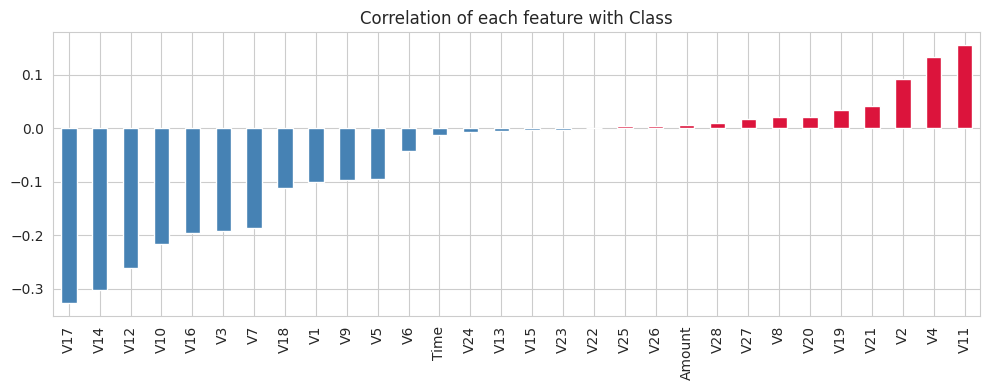

In [5]:
# Features most correlated with fraud
corr = df.corr()['Class'].drop('Class').sort_values()
plt.figure(figsize=(10,4))
corr.plot(kind='bar', color=np.where(corr>0,'crimson','steelblue'))
plt.title('Correlation of each feature with Class'); plt.tight_layout(); plt.show()

## 4. Data Cleaning
Remove exact duplicate rows (they leak between train/test and inflate scores).

In [6]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Removed {before-len(df)} duplicates -> {df.shape}')
print(df['Class'].value_counts())

Removed 1081 duplicates -> (283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


## 5. Train / Test Split
Stratified split so both sets keep the same fraud ratio. **The test set is never touched by SMOTE.**

In [7]:
X = df.drop('Class', axis=1)
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| fraud =', y_train.sum())
print('Test :', X_test.shape,  '| fraud =', y_test.sum())

Train: (226980, 30) | fraud = 378
Test : (56746, 30) | fraud = 95


## 6. Feature Scaling
`V1–V28` are already PCA-scaled. Only `Time` and `Amount` need scaling. `RobustScaler` is used because `Amount` has big outliers. The scaler is fit on **train only** to avoid leakage.

In [8]:
scaler = RobustScaler()
X_train, X_test = X_train.copy(), X_test.copy()
X_train[['Time','Amount']] = scaler.fit_transform(X_train[['Time','Amount']])
X_test[['Time','Amount']]  = scaler.transform(X_test[['Time','Amount']])
X_train.head(3)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
225399,0.7017,2.2390,-1.7245,-2.1515,-2.5778,0.9937,3.5655,-1.7860,0.8601,-1.2640,...,-0.3238,-0.1496,-0.0493,0.2784,0.6847,-0.2190,-0.1592,0.0379,-0.0499,0.1375
133746,-0.0482,-1.3151,1.6308,0.5970,-0.0384,-0.4046,-0.9657,0.2122,0.7354,-1.2679,...,-0.0676,-0.2389,-0.9468,0.3239,0.5156,-0.7130,-0.2665,-0.0178,0.0511,-0.2091
185792,0.4969,1.9088,0.0212,-2.0880,0.1293,1.1615,0.6052,-0.0224,0.1803,0.2838,...,-0.2105,0.2936,1.0958,-0.0449,-1.6895,0.1061,0.0078,0.0452,-0.0531,-0.0988


## 7. Apply SMOTE (training data only)
SMOTE creates *synthetic* fraud samples by interpolating between existing fraud points and their nearest neighbours, so the classes become balanced (50:50).

Before SMOTE: {0: np.int64(226602), 1: np.int64(378)}
After  SMOTE: {0: np.int64(226602), 1: np.int64(226602)}


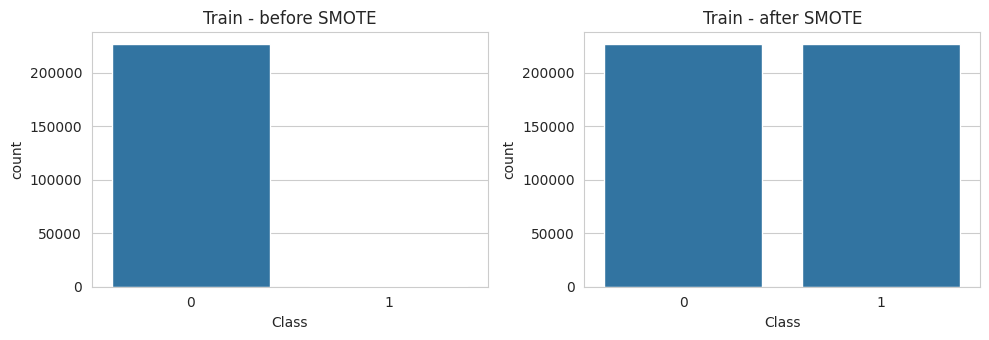

In [9]:
smote = SMOTE(sampling_strategy=1.0, k_neighbors=5, random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print('Before SMOTE:', dict(y_train.value_counts()))
print('After  SMOTE:', dict(pd.Series(y_train_sm).value_counts()))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(x=y_train, ax=ax[0]); ax[0].set_title('Train - before SMOTE')
sns.countplot(x=y_train_sm, ax=ax[1]); ax[1].set_title('Train - after SMOTE')
plt.tight_layout(); plt.show()

## 8. Models & Evaluation Helper
All models are evaluated on the **same untouched test set**, so before/after SMOTE results are directly comparable.

In [10]:
def get_models():
    return {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        'Decision Tree'      : DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
        'Random Forest'      : RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=RANDOM_STATE),
        'XGBoost'            : XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.8,
                                             eval_metric='logloss', n_jobs=-1, random_state=RANDOM_STATE),
        'LightGBM'           : LGBMClassifier(n_estimators=200, learning_rate=0.1, num_leaves=31,
                                              n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
    }

results, fitted, probas = [], {}, {}

def evaluate(name, setting, model, Xtr, ytr):
    t0 = time.time()
    model.fit(Xtr, ytr)
    train_time = time.time() - t0
    pred  = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name, 'Setting': setting,
        'Accuracy' : accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall'   : recall_score(y_test, pred),
        'F1'       : f1_score(y_test, pred),
        'ROC-AUC'  : roc_auc_score(y_test, proba),
        'PR-AUC'   : average_precision_score(y_test, proba),
        'Train time (s)': train_time})
    fitted[(name, setting)] = model
    probas[(name, setting)] = proba
    print(f'{setting:12s} | {name:20s} | acc={results[-1]["Accuracy"]:.5f} | recall={results[-1]["Recall"]:.4f} | F1={results[-1]["F1"]:.4f} | {train_time:.1f}s')

## 9. Training WITHOUT SMOTE (baseline)

In [11]:
for name, model in get_models().items():
    evaluate(name, 'Before SMOTE', model, X_train, y_train)

Before SMOTE | Logistic Regression  | acc=0.99915 | recall=0.5895 | F1=0.7000 | 1.0s


Before SMOTE | Decision Tree        | acc=0.99937 | recall=0.7053 | F1=0.7882 | 10.8s


Before SMOTE | Random Forest        | acc=0.99951 | recall=0.7263 | F1=0.8313 | 202.2s


Before SMOTE | XGBoost              | acc=0.99951 | recall=0.7368 | F1=0.8333 | 8.2s


Before SMOTE | LightGBM             | acc=0.99785 | recall=0.5579 | F1=0.4649 | 7.7s


## 10. Training WITH SMOTE

In [12]:
for name, model in get_models().items():
    evaluate(name, 'After SMOTE', model, X_train_sm, y_train_sm)

After SMOTE  | Logistic Regression  | acc=0.97401 | recall=0.8737 | F1=0.1012 | 3.4s


After SMOTE  | Decision Tree        | acc=0.98744 | recall=0.8421 | F1=0.1833 | 20.2s


After SMOTE  | Random Forest        | acc=0.99914 | recall=0.8000 | F1=0.7562 | 356.9s


After SMOTE  | XGBoost              | acc=0.99901 | recall=0.8000 | F1=0.7308 | 15.3s


After SMOTE  | LightGBM             | acc=0.99917 | recall=0.7789 | F1=0.7590 | 16.4s


## 11. Comparison: Before vs After SMOTE

In [13]:
res = pd.DataFrame(results)
res.sort_values(['Model','Setting'], ascending=[True, False])

,Model,Setting,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Train time (s)
1,Decision Tree,Before SMOTE,0.9994,0.8933,0.7053,0.7882,0.8701,0.6414,10.8219
6,Decision Tree,After SMOTE,0.9874,0.1028,0.8421,0.1833,0.8932,0.4657,20.2170
4,LightGBM,Before SMOTE,0.9979,0.3985,0.5579,0.4649,0.7335,0.3221,7.6575
9,LightGBM,After SMOTE,0.9992,0.7400,0.7789,0.7590,0.9544,0.7921,16.3582
0,Logistic Regression,Before SMOTE,0.9992,0.8615,0.5895,0.7000,0.9575,0.6951,0.9988
5,Logistic Regression,After SMOTE,0.9740,0.0537,0.8737,0.1012,0.9600,0.6729,3.4328
2,Random Forest,Before SMOTE,0.9995,0.9718,0.7263,0.8313,0.9668,0.7954,202.1669
7,Random Forest,After SMOTE,0.9991,0.7170,0.8000,0.7562,0.9769,0.7957,356.8892
3,XGBoost,Before SMOTE,0.9995,0.9589,0.7368,0.8333,0.9777,0.8248,8.1735
8,XGBoost,After SMOTE,0.9990,0.6726,0.8000,0.7308,0.9680,0.8225,15.3293


In [14]:
acc = res.pivot(index='Model', columns='Setting', values='Accuracy')[['Before SMOTE','After SMOTE']]
acc['Change'] = acc['After SMOTE'] - acc['Before SMOTE']
print('ACCURACY: before vs after SMOTE'); display(acc)

for m in ['Precision','Recall','F1','PR-AUC']:
    t = res.pivot(index='Model', columns='Setting', values=m)[['Before SMOTE','After SMOTE']]
    t['Change'] = t['After SMOTE'] - t['Before SMOTE']
    print(f'\n{m.upper()}: before vs after SMOTE'); display(t)

ACCURACY: before vs after SMOTE


Setting,Before SMOTE,After SMOTE,Change
Model,,,
Decision Tree,0.9994,0.9874,-0.0119
LightGBM,0.9979,0.9992,0.0013
Logistic Regression,0.9992,0.9740,-0.0251
Random Forest,0.9995,0.9991,-0.0004
XGBoost,0.9995,0.9990,-0.0005



PRECISION: before vs after SMOTE


Setting,Before SMOTE,After SMOTE,Change
Model,,,
Decision Tree,0.8933,0.1028,-0.7905
LightGBM,0.3985,0.7400,0.3415
Logistic Regression,0.8615,0.0537,-0.8079
Random Forest,0.9718,0.7170,-0.2548
XGBoost,0.9589,0.6726,-0.2863



RECALL: before vs after SMOTE


Setting,Before SMOTE,After SMOTE,Change
Model,,,
Decision Tree,0.7053,0.8421,0.1368
LightGBM,0.5579,0.7789,0.2211
Logistic Regression,0.5895,0.8737,0.2842
Random Forest,0.7263,0.8000,0.0737
XGBoost,0.7368,0.8000,0.0632



F1: before vs after SMOTE


Setting,Before SMOTE,After SMOTE,Change
Model,,,
Decision Tree,0.7882,0.1833,-0.6050
LightGBM,0.4649,0.7590,0.2941
Logistic Regression,0.7000,0.1012,-0.5988
Random Forest,0.8313,0.7562,-0.0751
XGBoost,0.8333,0.7308,-0.1026



PR-AUC: before vs after SMOTE


Setting,Before SMOTE,After SMOTE,Change
Model,,,
Decision Tree,0.6414,0.4657,-0.1757
LightGBM,0.3221,0.7921,0.4700
Logistic Regression,0.6951,0.6729,-0.0222
Random Forest,0.7954,0.7957,0.0003
XGBoost,0.8248,0.8225,-0.0022


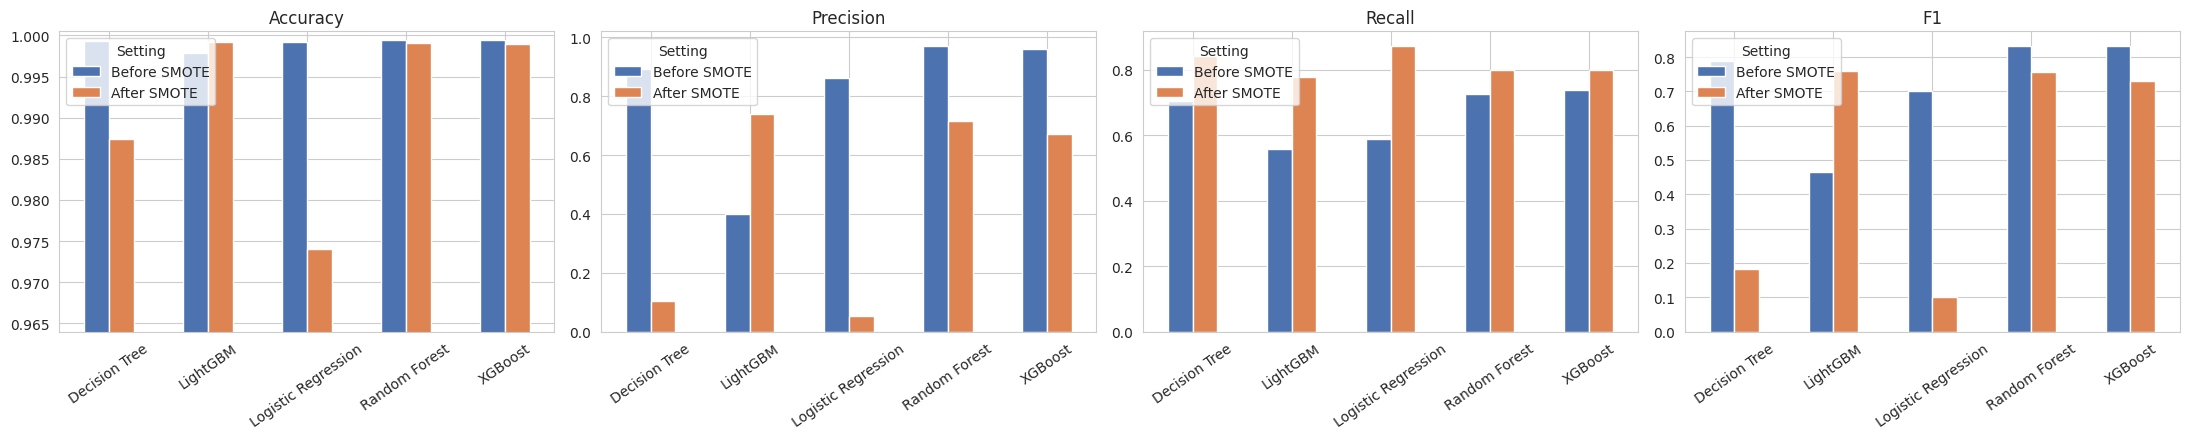

In [15]:
metrics = ['Accuracy','Precision','Recall','F1']
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, m in zip(axes, metrics):
    p = res.pivot(index='Model', columns='Setting', values=m)[['Before SMOTE','After SMOTE']]
    p.plot(kind='bar', ax=ax, color=['#4c72b0','#dd8452'])
    ax.set_title(m); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=35)
    if m == 'Accuracy': ax.set_ylim(p.min().min()-0.01, 1.0005)
plt.tight_layout(); plt.show()

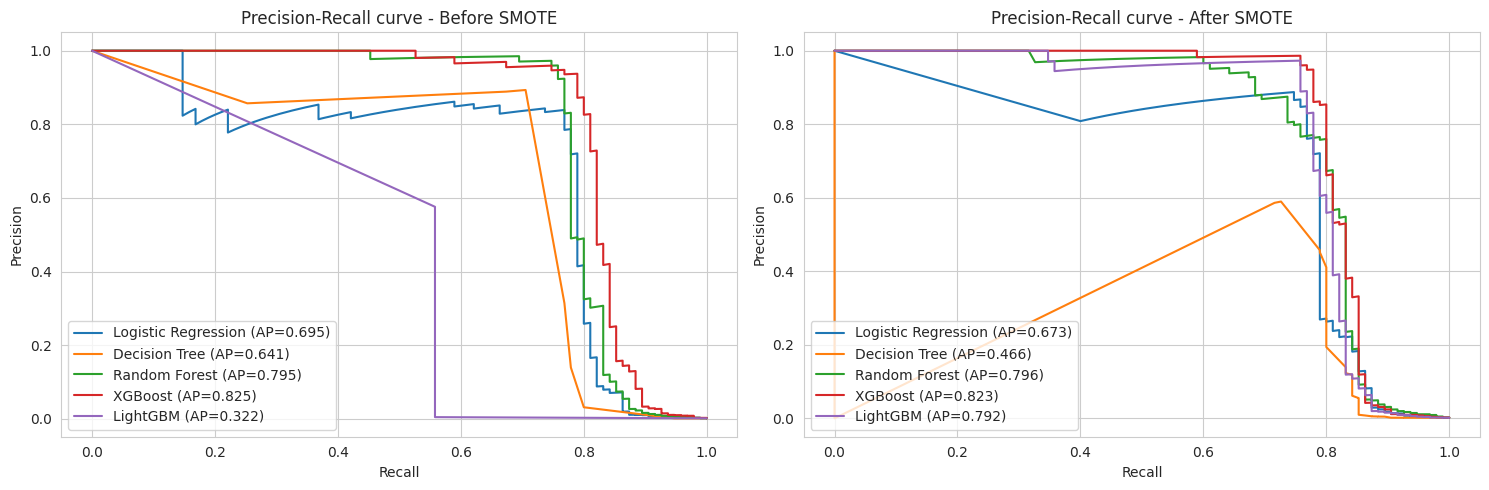

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, setting in zip(axes, ['Before SMOTE','After SMOTE']):
    for name in get_models():
        p, r, _ = precision_recall_curve(y_test, probas[(name, setting)])
        ax.plot(r, p, label=f"{name} (AP={average_precision_score(y_test, probas[(name, setting)]):.3f})")
    ax.set_title(f'Precision-Recall curve - {setting}'); ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.legend(loc='lower left')
plt.tight_layout(); plt.show()

## 12. Best Model

In [17]:
best_acc = res.loc[res['Accuracy'].idxmax()]
best_f1  = res.loc[res['F1'].idxmax()]
best_pr  = res.loc[res['PR-AUC'].idxmax()]

print('Best by ACCURACY :', best_acc['Model'], '|', best_acc['Setting'], f"| acc={best_acc['Accuracy']:.5f}  recall={best_acc['Recall']:.4f}  F1={best_acc['F1']:.4f}")
print('Best by F1-score :', best_f1['Model'],  '|', best_f1['Setting'],  f"| acc={best_f1['Accuracy']:.5f}  recall={best_f1['Recall']:.4f}  F1={best_f1['F1']:.4f}")
print('Best by PR-AUC   :', best_pr['Model'],  '|', best_pr['Setting'],  f"| PR-AUC={best_pr['PR-AUC']:.4f}")

print('\nTop 5 by accuracy:'); display(res.sort_values('Accuracy', ascending=False).head(5)[['Model','Setting','Accuracy','Precision','Recall','F1','PR-AUC']])

Best by ACCURACY : Random Forest | Before SMOTE | acc=0.99951  recall=0.7263  F1=0.8313
Best by F1-score : XGBoost | Before SMOTE | acc=0.99951  recall=0.7368  F1=0.8333
Best by PR-AUC   : XGBoost | Before SMOTE | PR-AUC=0.8248

Top 5 by accuracy:


,Model,Setting,Accuracy,Precision,Recall,F1,PR-AUC
3,XGBoost,Before SMOTE,0.9995,0.9589,0.7368,0.8333,0.8248
2,Random Forest,Before SMOTE,0.9995,0.9718,0.7263,0.8313,0.7954
1,Decision Tree,Before SMOTE,0.9994,0.8933,0.7053,0.7882,0.6414
9,LightGBM,After SMOTE,0.9992,0.7400,0.7789,0.7590,0.7921
0,Logistic Regression,Before SMOTE,0.9992,0.8615,0.5895,0.7000,0.6951


Detailed report for: ('XGBoost', 'Before SMOTE')
              precision    recall  f1-score   support

       Legit     0.9996    0.9999    0.9998     56651
       Fraud     0.9589    0.7368    0.8333        95

    accuracy                         0.9995     56746
   macro avg     0.9792    0.8684    0.9165     56746
weighted avg     0.9995    0.9995    0.9995     56746



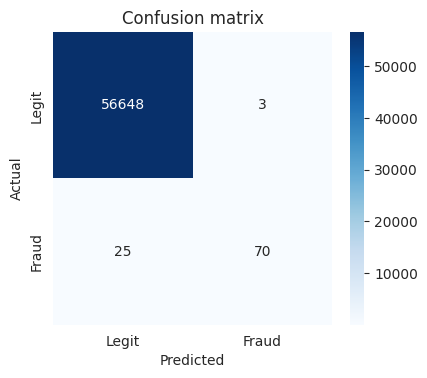

In [18]:
key = (best_f1['Model'], best_f1['Setting'])
best_model = fitted[key]
pred = best_model.predict(X_test)
print('Detailed report for:', key)
print(classification_report(y_test, pred, target_names=['Legit','Fraud'], digits=4))

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(4.5,3.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Legit','Fraud'], yticklabels=['Legit','Fraud'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix'); plt.show()

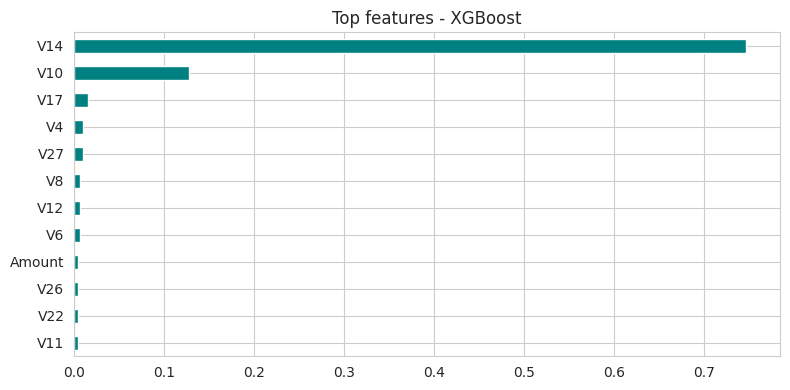

In [19]:
if hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(12)
    plt.figure(figsize=(8,4)); imp[::-1].plot(kind='barh', color='teal'); plt.title(f'Top features - {key[0]}'); plt.tight_layout(); plt.show()

## 13. Save the Model & Real-Time Inference Function

In [20]:
joblib.dump({'model': best_model, 'scaler': scaler, 'features': list(X_train.columns)}, 'fraud_engine.joblib')

engine = joblib.load('fraud_engine.joblib')

def predict_transaction(txn: dict, threshold=0.5):
    """txn: dict with keys Time, V1..V28, Amount -> returns fraud probability and decision."""
    row = pd.DataFrame([txn])[engine['features']].copy()
    row[['Time','Amount']] = engine['scaler'].transform(row[['Time','Amount']])
    p = float(engine['model'].predict_proba(row)[0, 1])
    return {'fraud_probability': round(p, 4), 'decision': 'FRAUD - BLOCK' if p >= threshold else 'LEGIT - APPROVE'}

# Demo on raw (unscaled) rows from the original data
raw = pd.read_csv(DATA_PATH).drop_duplicates()
for label in [1, 0]:
    sample = raw[raw.Class == label].sample(1, random_state=1).drop('Class', axis=1).iloc[0].to_dict()
    t0 = time.time(); out = predict_transaction(sample)
    print(f'Actual class={label} ->', out, f'({(time.time()-t0)*1000:.1f} ms)')

Actual class=1 -> {'fraud_probability': 0.9997, 'decision': 'FRAUD - BLOCK'} (5.5 ms)
Actual class=0 -> {'fraud_probability': 0.0, 'decision': 'LEGIT - APPROVE'} (7.3 ms)


## 14. Conclusion
*(the cell below prints the conclusion from the actual results)*

In [21]:
a = res.pivot(index='Model', columns='Setting', values='Accuracy')
r = res.pivot(index='Model', columns='Setting', values='Recall')
f = res.pivot(index='Model', columns='Setting', values='F1')
print('CONCLUSION')
print('-'*70)
print(f"1. Fraud is only {y.mean()*100:.3f}% of the data, so a do-nothing model already gets ~{(1-y.mean())*100:.2f}% accuracy.")
print(f"2. Accuracy before SMOTE ranged {a['Before SMOTE'].min():.4f}-{a['Before SMOTE'].max():.4f}; after SMOTE {a['After SMOTE'].min():.4f}-{a['After SMOTE'].max():.4f}.")
print(f"3. Average recall (fraud caught): {r['Before SMOTE'].mean():.4f} before -> {r['After SMOTE'].mean():.4f} after SMOTE.")
print(f"4. Average F1: {f['Before SMOTE'].mean():.4f} before -> {f['After SMOTE'].mean():.4f} after SMOTE.")
print(f"5. Highest accuracy : {best_acc['Model']} ({best_acc['Setting']}) = {best_acc['Accuracy']:.5f}")
print(f"6. Best F1 / overall: {best_f1['Model']} ({best_f1['Setting']}) -> F1={best_f1['F1']:.4f}, recall={best_f1['Recall']:.4f}, precision={best_f1['Precision']:.4f}")

CONCLUSION
----------------------------------------------------------------------
1. Fraud is only 0.167% of the data, so a do-nothing model already gets ~99.83% accuracy.
2. Accuracy before SMOTE ranged 0.9979-0.9995; after SMOTE 0.9740-0.9992.
3. Average recall (fraud caught): 0.6632 before -> 0.8189 after SMOTE.
4. Average F1: 0.7236 before -> 0.5061 after SMOTE.
5. Highest accuracy : Random Forest (Before SMOTE) = 0.99951
6. Best F1 / overall: XGBoost (Before SMOTE) -> F1=0.8333, recall=0.7368, precision=0.9589
